In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
print(statsmodels.__version__)

sns.set_theme(style="whitegrid")

print("AirScope initialized successfully!")

0.15.0
AirScope initialized successfully!


In [72]:
from pathlib import Path

data_path = Path("data/city_day.csv")

df = pd.read_csv(data_path)

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
print("Number of cities:", df["City"].nunique())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

df.head()

Dataset loaded successfully!
Rows and columns: (29531, 16)
Number of cities: 26
Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [73]:

# ==========================================
# AIRSCOPE: DATA PREPARATION
# ==========================================

# 1. Check and clean column names
df.columns = df.columns.str.strip()

# 2. Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# 3. Convert pollutant and AQI columns into numeric format
numeric_cols = [
    "AQI", "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3", "Benzene",
    "Toluene", "Xylene"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# 4. Remove rows without a valid city or date
df = df.dropna(subset=["City", "Date"]).copy()

# 5. Create date-related columns for time-series analysis
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Day"] = df["Date"].dt.day
df["Day_of_Week"] = df["Date"].dt.day_name()

# 6. Create AQI categories if they are missing
if "AQI_Bucket" not in df.columns:
    df["AQI_Bucket"] = pd.cut(
        df["AQI"],
        bins=[-np.inf, 50, 100, 200, 300, 400, np.inf],
        labels=[
            "Good",
            "Satisfactory",
            "Moderate",
            "Poor",
            "Very Poor",
            "Severe"
        ]
    )

# 7. Display preparation summary
print("AirScope data preparation completed!")
print("-" * 40)
print("Dataset shape:", df.shape)
print("Number of cities:", df["City"].nunique())
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Missing AQI values:", df["AQI"].isna().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nAvailable columns:")
print(df.columns.tolist())

display(df.head())


AirScope data preparation completed!
----------------------------------------
Dataset shape: (29531, 21)
Number of cities: 26
Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00
Missing AQI values: 4681
Duplicate rows: 0

Available columns:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket', 'Year', 'Month', 'Month_Name', 'Day', 'Day_of_Week']


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,...,Benzene,Toluene,Xylene,AQI,AQI_Bucket,Year,Month,Month_Name,Day,Day_of_Week
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,...,0.00,0.02,0.00,NaN,NaN,2015,1,January,1,Thursday
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,...,3.68,5.50,3.77,NaN,NaN,2015,1,January,2,Friday
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,...,6.80,16.40,2.25,NaN,NaN,2015,1,January,3,Saturday
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,...,4.43,10.14,1.00,NaN,NaN,2015,1,January,4,Sunday
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,...,7.01,18.89,2.78,NaN,NaN,2015,1,January,5,Monday


In [74]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nValid AQI records:", df["AQI"].count())

print("\nRecords per city:")
print(df["City"].value_counts())

Missing values in each column:
City               0
Date               0
PM2.5           4598
PM10           11140
NO              3582
NO2             3585
NOx             4185
NH3            10328
CO              2059
SO2             3854
O3              4022
Benzene         5623
Toluene         8041
Xylene         18109
AQI             4681
AQI_Bucket      4681
Year               0
Month              0
Month_Name         0
Day                0
Day_of_Week        0
dtype: int64

Exact duplicate rows: 0

Valid AQI records: 24850

Records per city:
City
Ahmedabad             2009
Bengaluru             2009
Chennai               2009
Delhi                 2009
Lucknow               2009
Mumbai                2009
Hyderabad             2006
Patna                 1858
Gurugram              1679
Visakhapatnam         1462
Amritsar              1221
Jorapokhar            1169
Jaipur                1114
Thiruvananthapuram    1112
Amaravati              951
Brajrajnagar           938
Talcher 

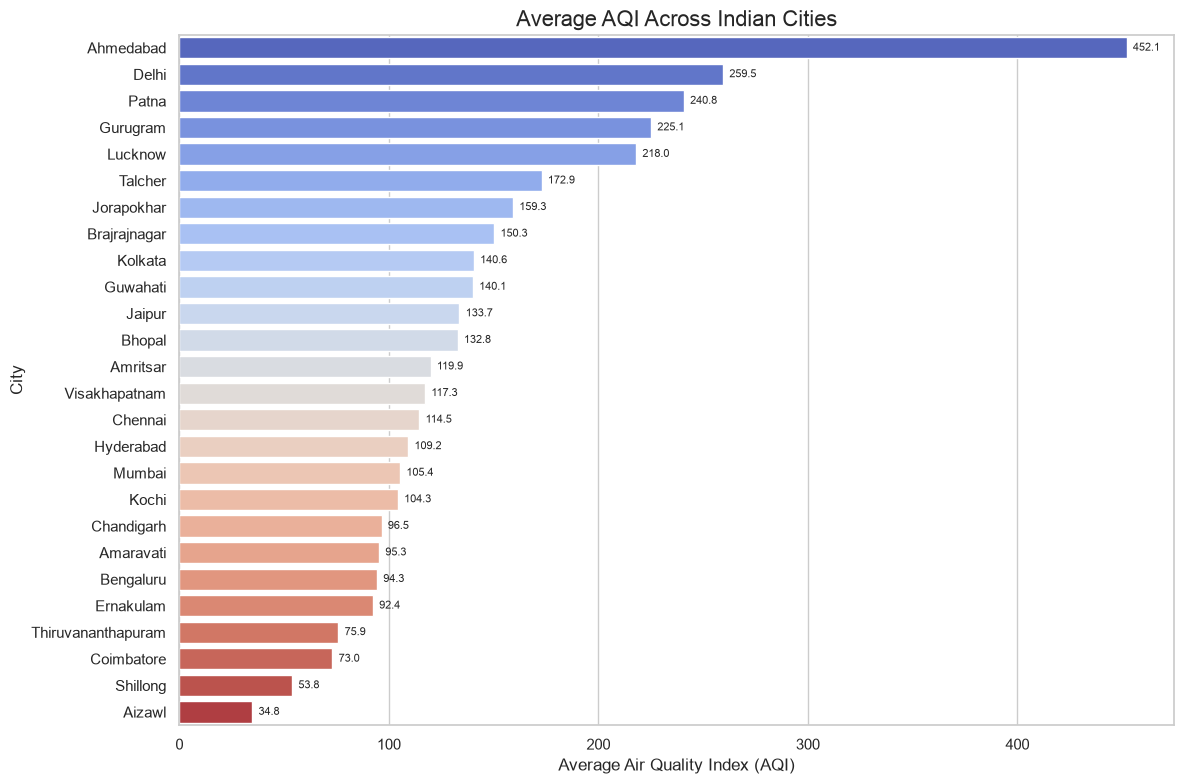

In [75]:
#BAR PLOTTING AVERAGE AQI ACROSS CITIES
city_aqi = (
    df.groupby("City")["AQI"]
    .mean()
    .dropna()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    x=city_aqi.values,
    y=city_aqi.index,
    hue=city_aqi.index,
    palette="coolwarm",
    legend=False
)

for i, value in enumerate(city_aqi.values):
    ax.text(value + 3, i, f"{value:.1f}", va="center", fontsize=8)

plt.title("Average AQI Across Indian Cities", fontsize=16)
plt.xlabel("Average Air Quality Index (AQI)")
plt.ylabel("City")
plt.tight_layout()
plt.show()


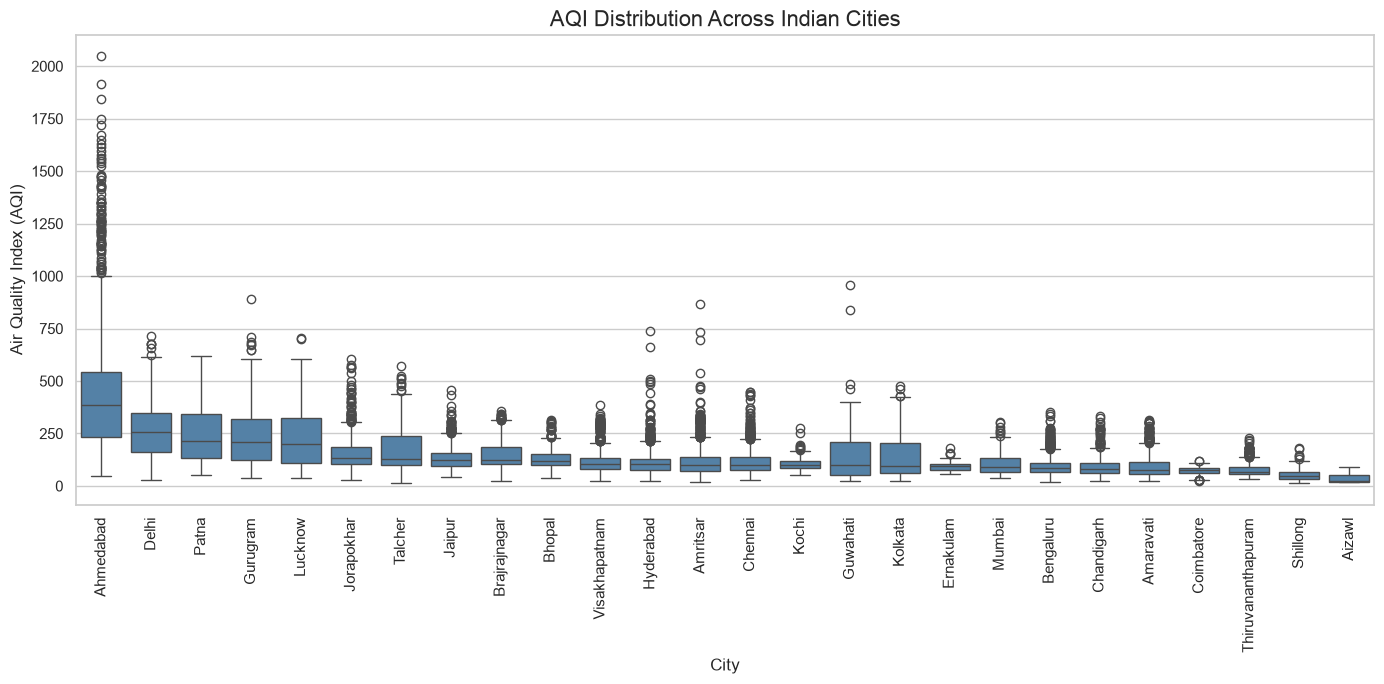

In [76]:
#BOX PLOTTING :)
plt.figure(figsize=(14, 7))

city_order = (
    df.groupby("City")["AQI"]
    .median()
    .dropna()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=df,
    x="City",
    y="AQI",
    order=city_order,
    color="steelblue"
)

plt.title("AQI Distribution Across Indian Cities", fontsize=16)
plt.xlabel("City")
plt.ylabel("Air Quality Index (AQI)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

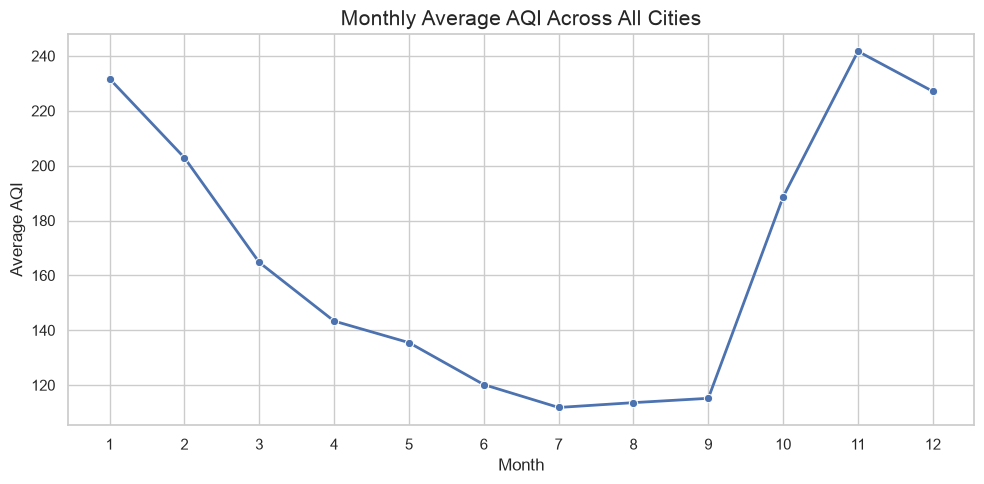

In [77]:
df["Month"] = df["Date"].dt.month

monthly_aqi = df.groupby("Month")["AQI"].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_aqi.index,
    y=monthly_aqi.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Average AQI Across All Cities", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

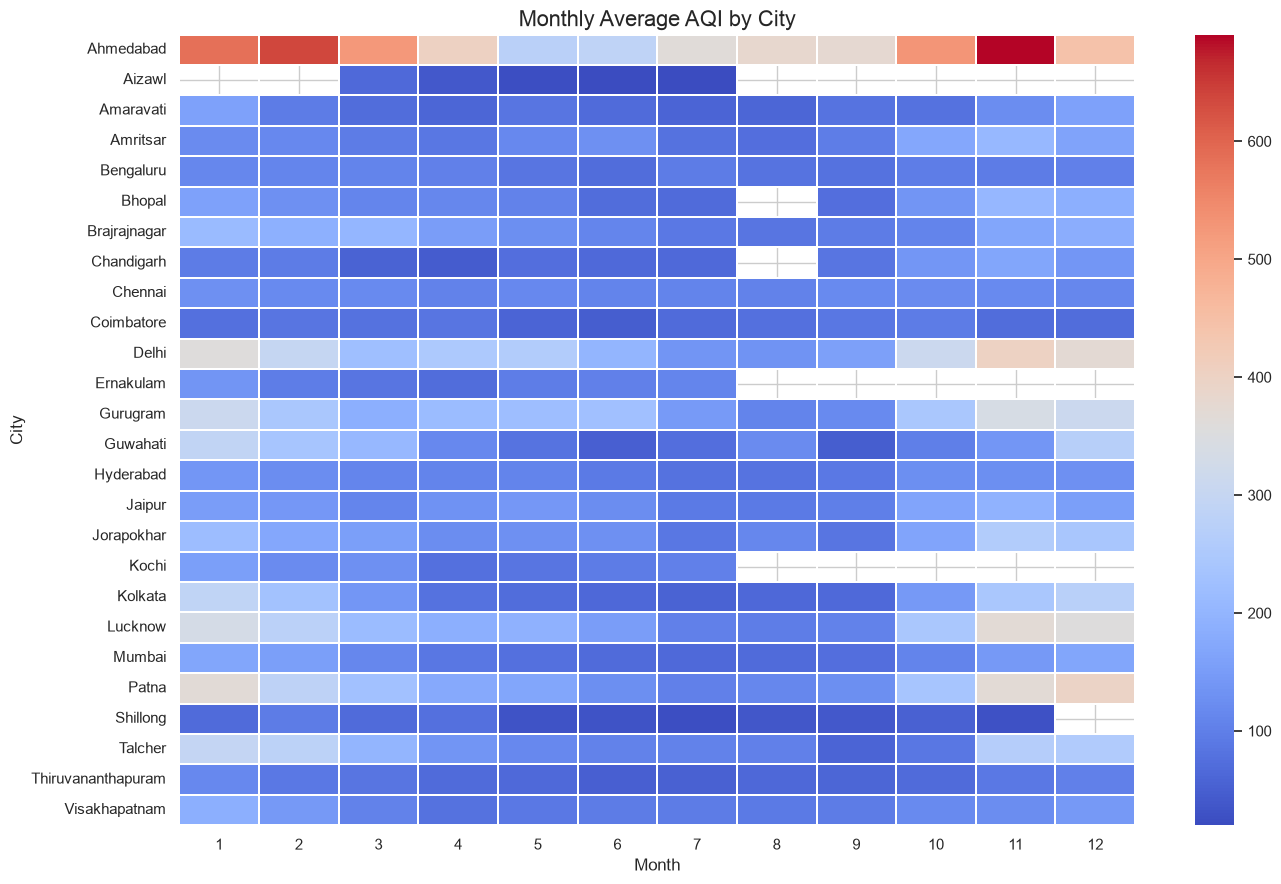

In [78]:
city_month_aqi = df.pivot_table(
    index="City",
    columns="Month",
    values="AQI",
    aggfunc="mean"
)

plt.figure(figsize=(14, 9))

sns.heatmap(
    city_month_aqi,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("Monthly Average AQI by City", fontsize=16)
plt.xlabel("Month")
plt.ylabel("City")
plt.tight_layout()
plt.show()

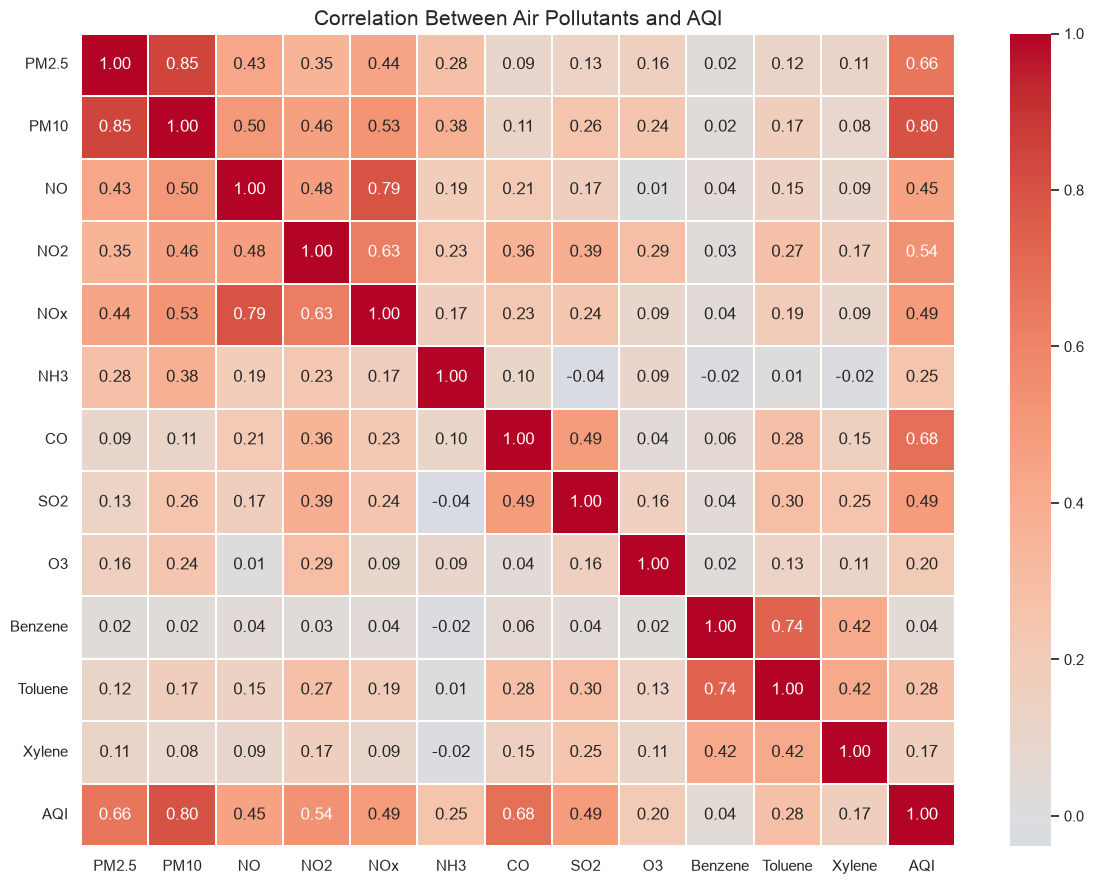

In [79]:
pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3", "Benzene",
    "Toluene", "Xylene", "AQI"
]

available_pollutants = [
    column for column in pollutants
    if column in df.columns
]

correlation = df[available_pollutants].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Correlation Between Air Pollutants and AQI", fontsize=15)
plt.tight_layout()
plt.show()

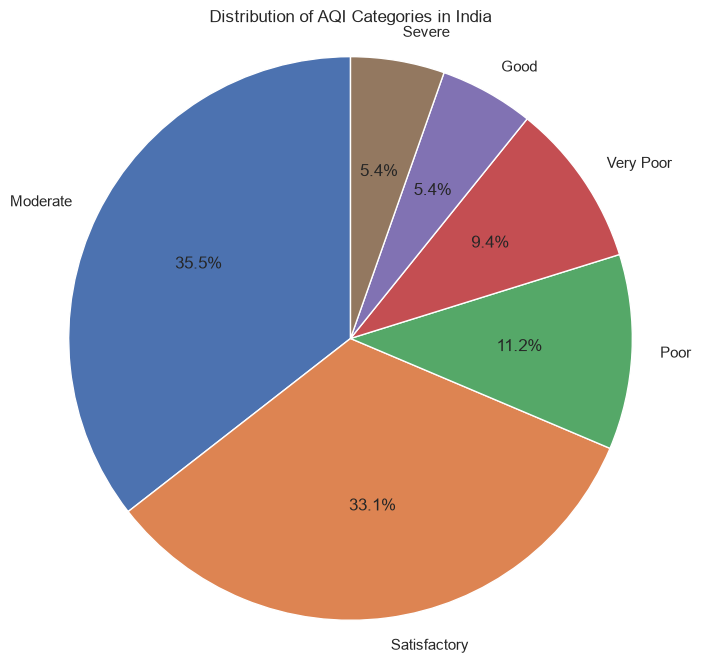

In [80]:
# Graph 6: AQI Category Distribution — Pie Chart

aqi_counts = df["AQI_Bucket"].dropna().value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    aqi_counts,
    labels=aqi_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of AQI Categories in India")
plt.axis("equal")
plt.show()

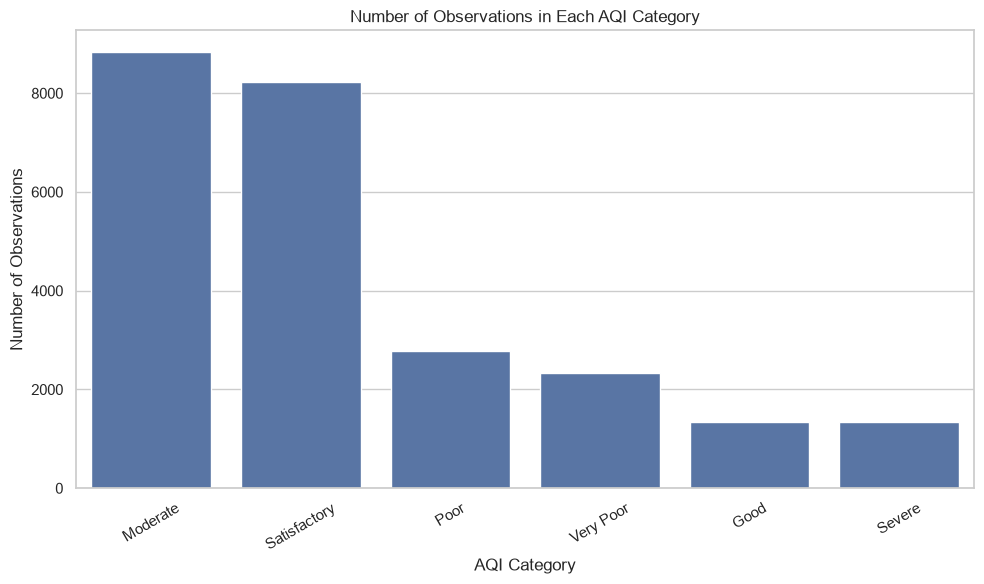

In [81]:
# Graph 7: Count Plot of AQI Categories

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="AQI_Bucket",
    order=df["AQI_Bucket"].value_counts().index
)

plt.title("Number of Observations in Each AQI Category")
plt.xlabel("AQI Category")
plt.ylabel("Number of Observations")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

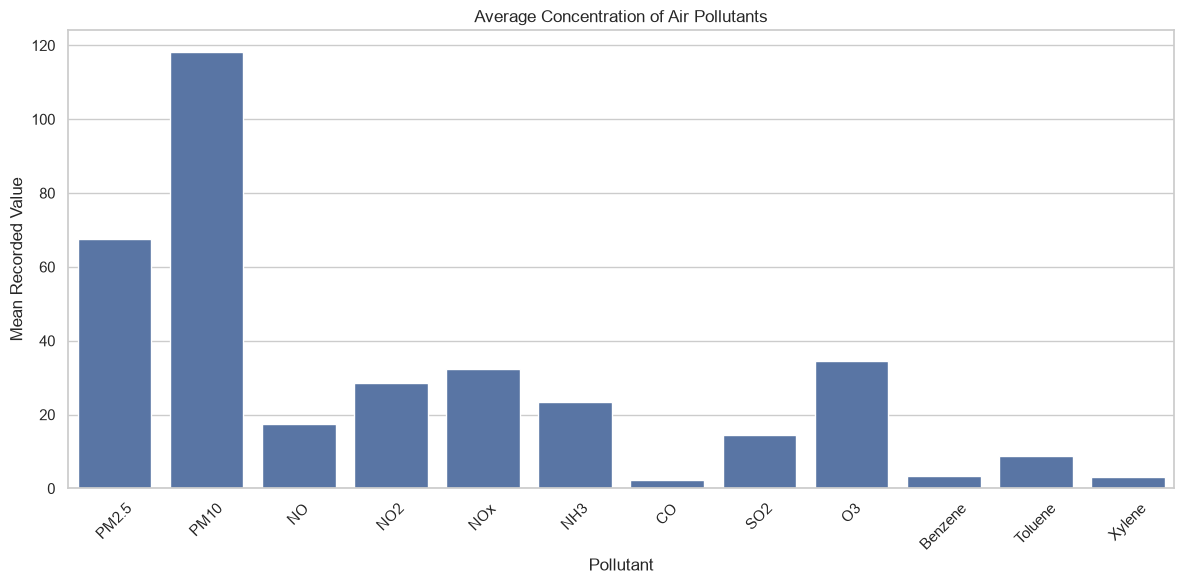

In [82]:
# Graph 8: Average Pollutant Concentrations

pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3", "Benzene",
    "Toluene", "Xylene"
]

available_pollutants = [
    col for col in pollutants if col in df.columns
]

pollutant_means = df[available_pollutants].mean().dropna()

plt.figure(figsize=(12, 6))
sns.barplot(
    x=pollutant_means.index,
    y=pollutant_means.values
)

plt.title("Average Concentration of Air Pollutants")
plt.xlabel("Pollutant")
plt.ylabel("Mean Recorded Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

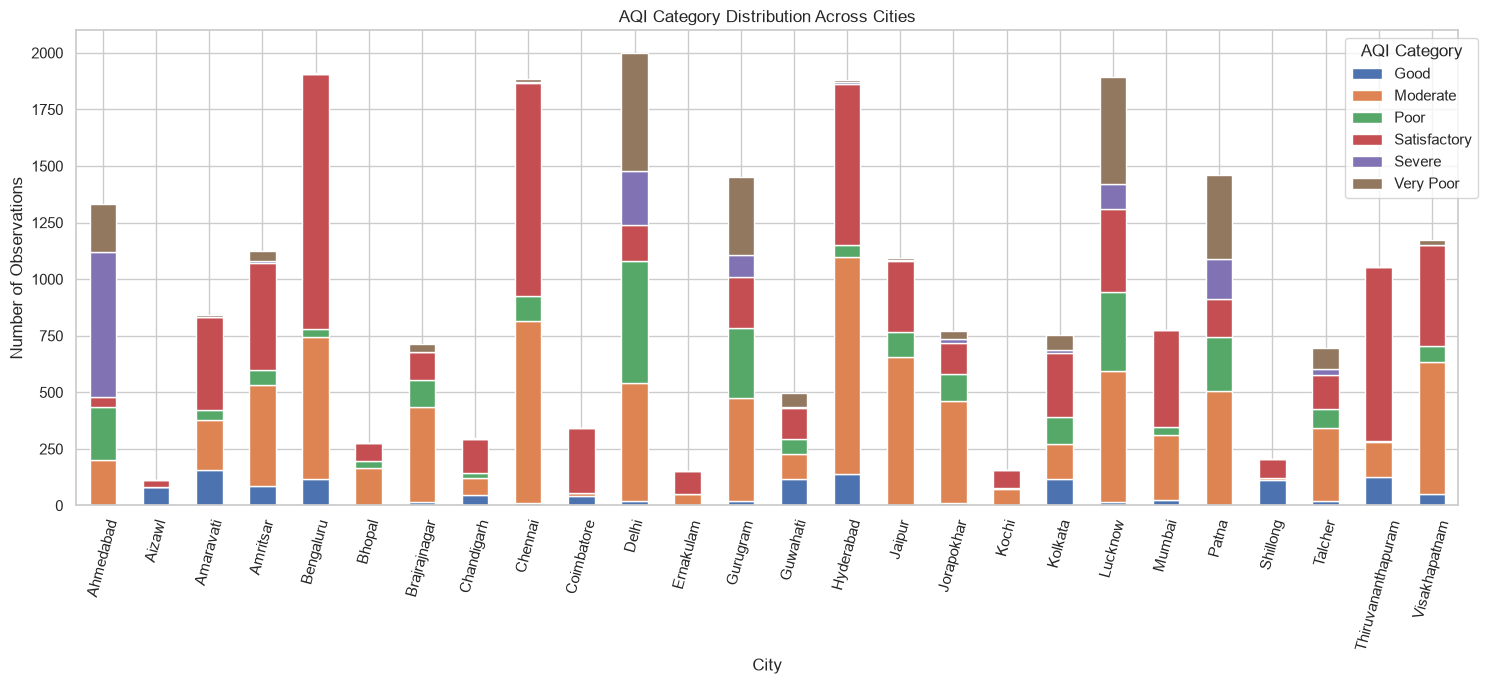

In [83]:
# Graph 9: Stacked Bar Chart — AQI Categories by City

city_category = pd.crosstab(df["City"], df["AQI_Bucket"])

city_category.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 7)
)

plt.title("AQI Category Distribution Across Cities")
plt.xlabel("City")
plt.ylabel("Number of Observations")
plt.xticks(rotation=75)
plt.legend(title="AQI Category", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

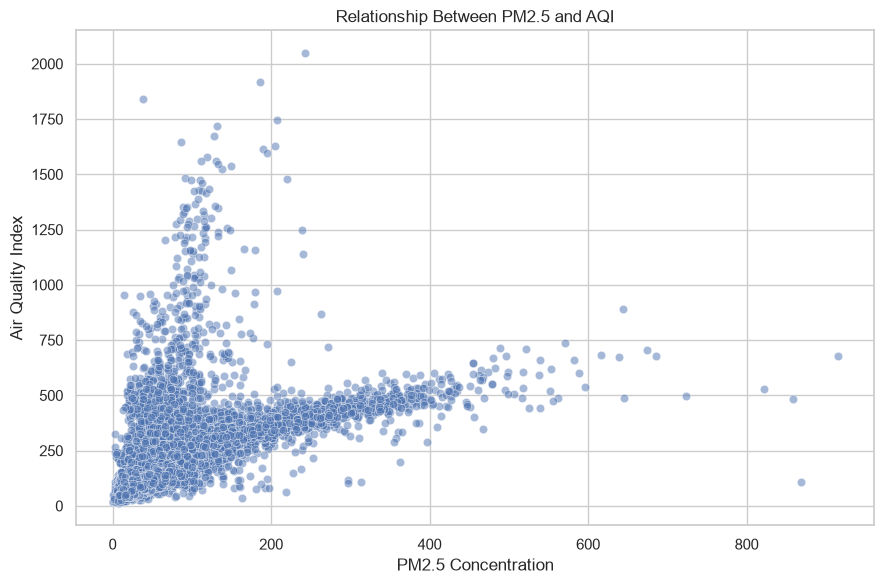

In [84]:
# Graph 10: PM2.5 vs AQI

plot_data = df[["PM2.5", "AQI"]].dropna()

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_data,
    x="PM2.5",
    y="AQI",
    alpha=0.5
)

plt.title("Relationship Between PM2.5 and AQI")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Air Quality Index")
plt.tight_layout()
plt.show()

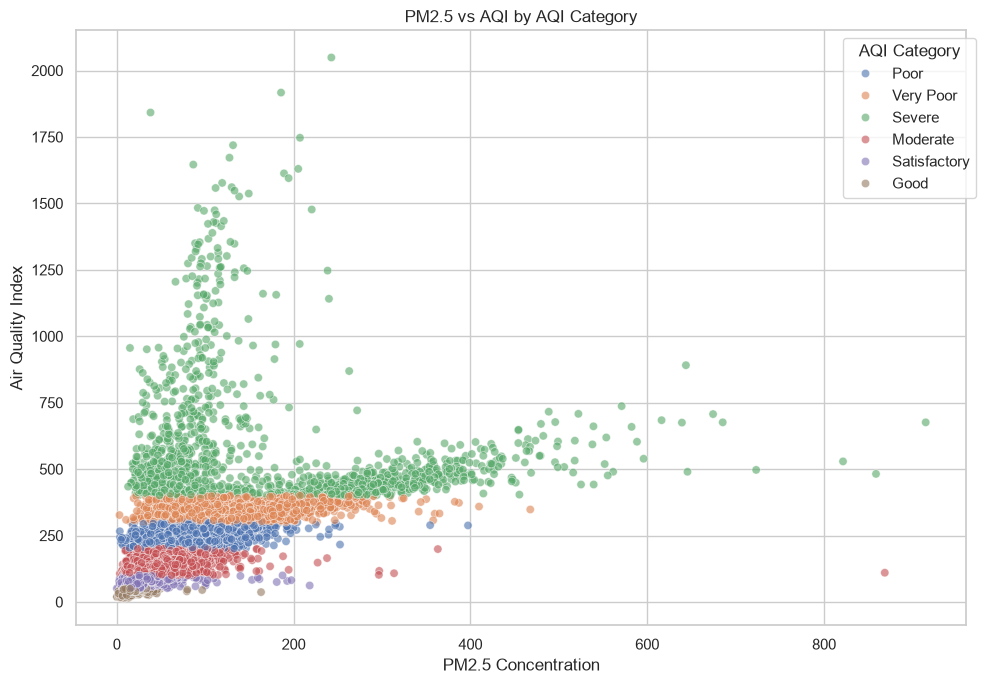

In [85]:
# Graph 11: Scatter Plot with AQI Categories

plot_data = df[["PM2.5", "AQI", "AQI_Bucket"]].dropna()

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=plot_data,
    x="PM2.5",
    y="AQI",
    hue="AQI_Bucket",
    alpha=0.6
)

plt.title("PM2.5 vs AQI by AQI Category")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Air Quality Index")
plt.legend(title="AQI Category", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

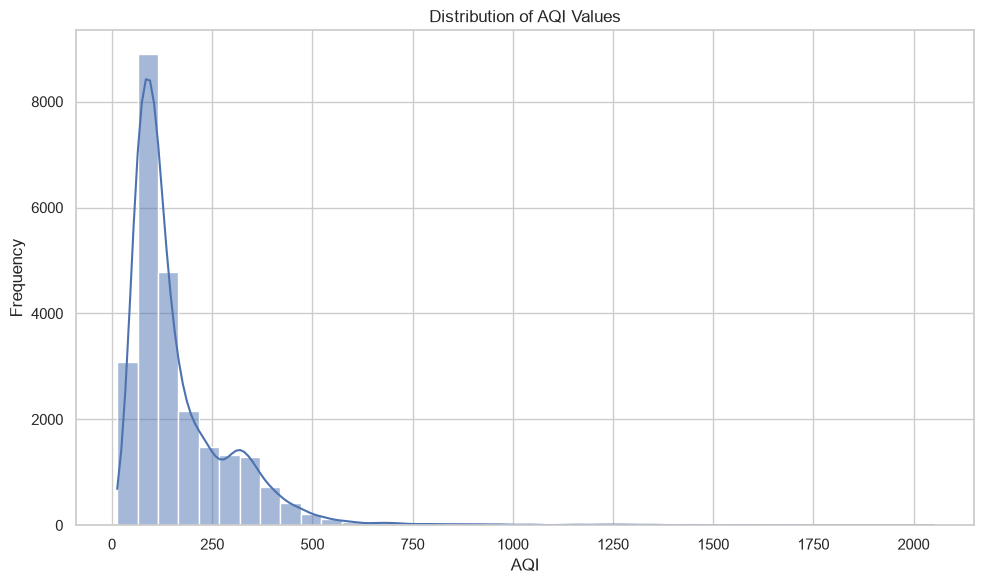

In [86]:
# Graph 12: AQI Histogram and KDE

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="AQI",
    bins=40,
    kde=True
)

plt.title("Distribution of AQI Values")
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

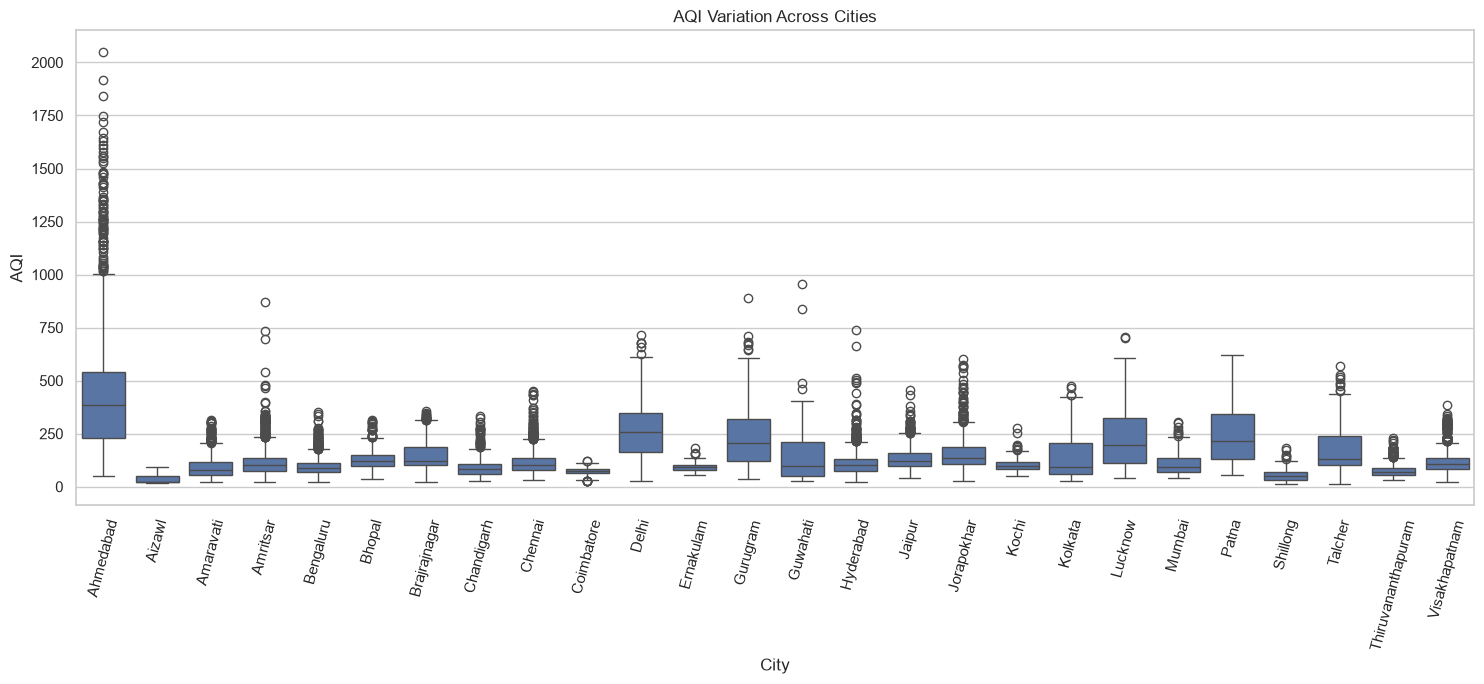

In [87]:
# Graph 13: AQI Distribution Across Cities

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=df,
    x="City",
    y="AQI"
)

plt.title("AQI Variation Across Cities")
plt.xlabel("City")
plt.ylabel("AQI")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

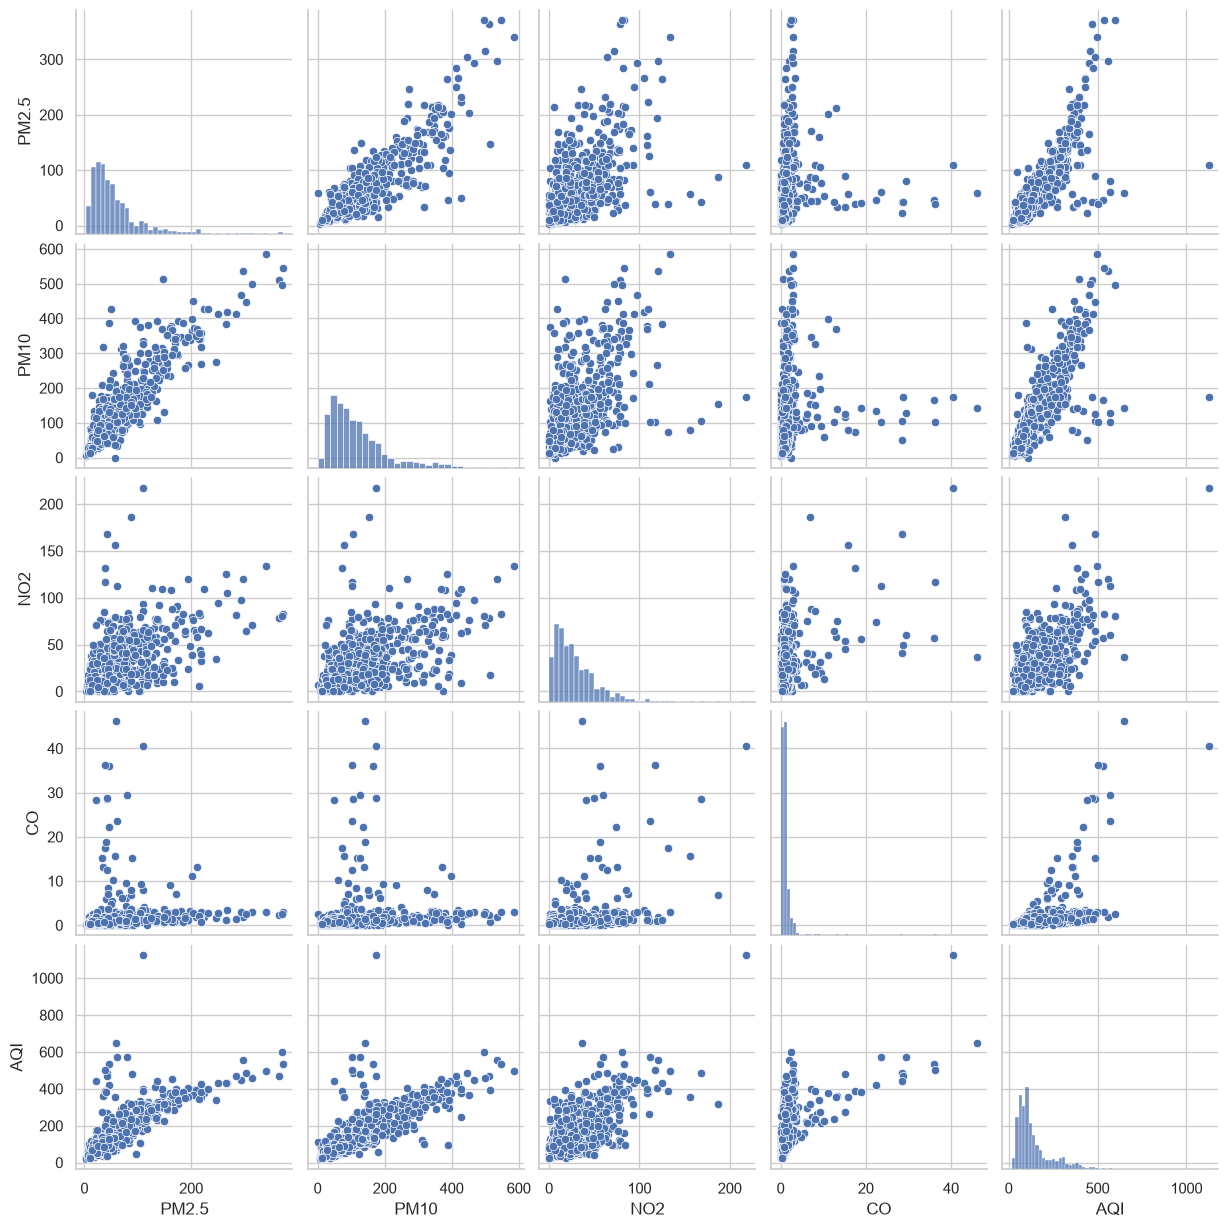

In [88]:
# Graph 14: Pair Plot of Selected Pollutants

pair_columns = ["PM2.5", "PM10", "NO2", "CO", "AQI"]
pair_data = df[pair_columns].dropna()

pair_data = pair_data.sample(
    n=min(1000, len(pair_data)),
    random_state=42
)

sns.pairplot(
    pair_data,
    diag_kind="hist"
)

plt.show()

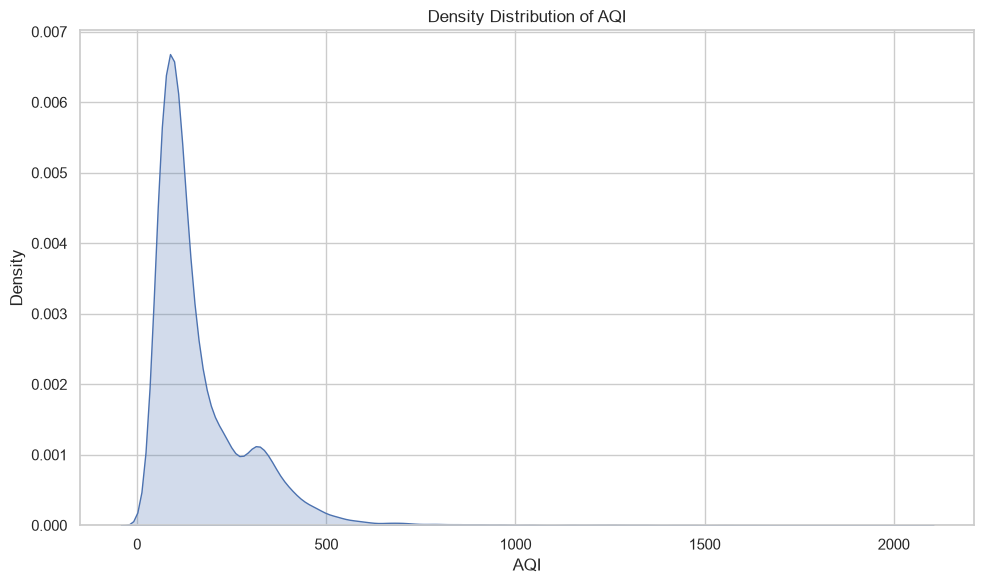

In [89]:
# Graph 15: AQI Density Plot

plt.figure(figsize=(10, 6))

sns.kdeplot(
    data=df,
    x="AQI",
    fill=True
)

plt.title("Density Distribution of AQI")
plt.xlabel("AQI")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

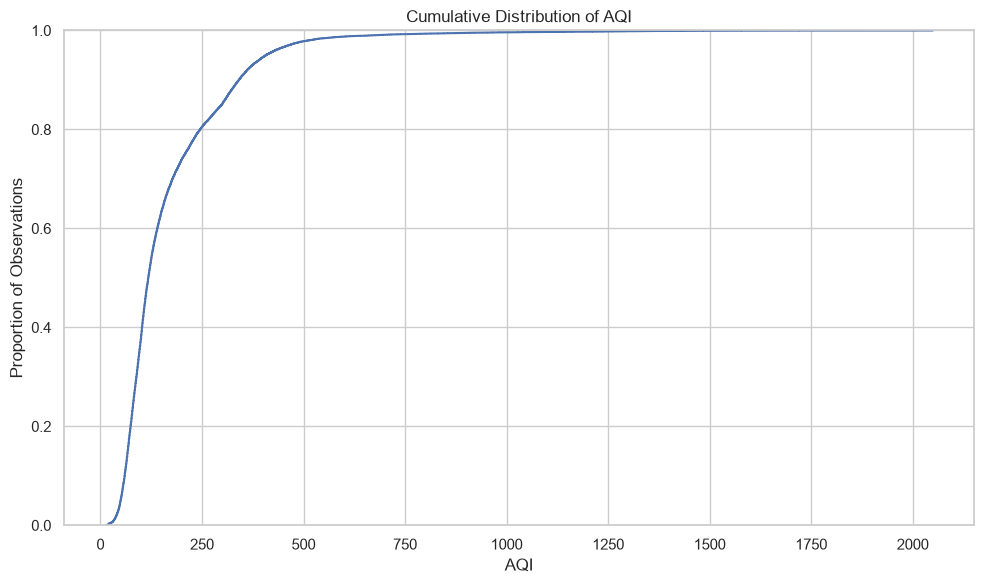

In [90]:
# Graph 16: ECDF of AQI

plt.figure(figsize=(10, 6))

sns.ecdfplot(
    data=df,
    x="AQI"
)

plt.title("Cumulative Distribution of AQI")
plt.xlabel("AQI")
plt.ylabel("Proportion of Observations")
plt.tight_layout()
plt.show()

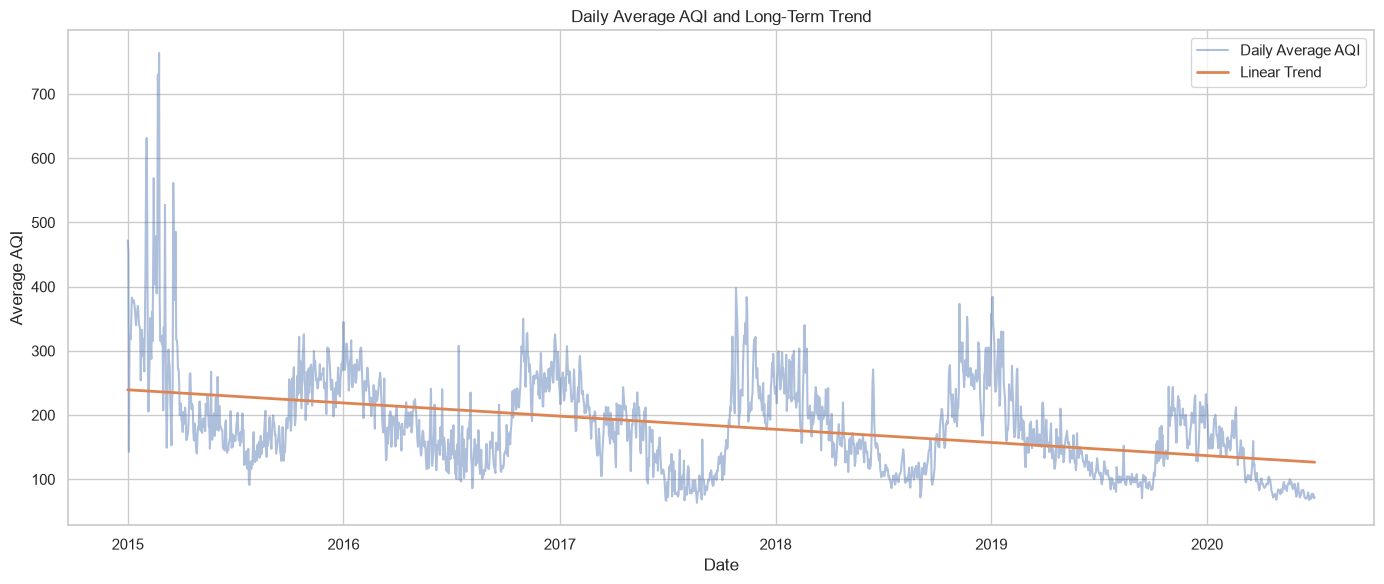

In [91]:
# Graph 17: Daily Average AQI with Trend Line

daily_aqi = (
    df.dropna(subset=["AQI"])
      .groupby("Date")["AQI"]
      .mean()
      .sort_index()
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_aqi.index,
    daily_aqi.values,
    alpha=0.45,
    label="Daily Average AQI"
)

if len(daily_aqi) > 1:
    x = np.arange(len(daily_aqi))
    coefficients = np.polyfit(x, daily_aqi.values, 1)
    trend = np.polyval(coefficients, x)

    plt.plot(
        daily_aqi.index,
        trend,
        linewidth=2,
        label="Linear Trend"
    )

plt.title("Daily Average AQI and Long-Term Trend")
plt.xlabel("Date")
plt.ylabel("Average AQI")
plt.legend()
plt.tight_layout()
plt.show()

In [92]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


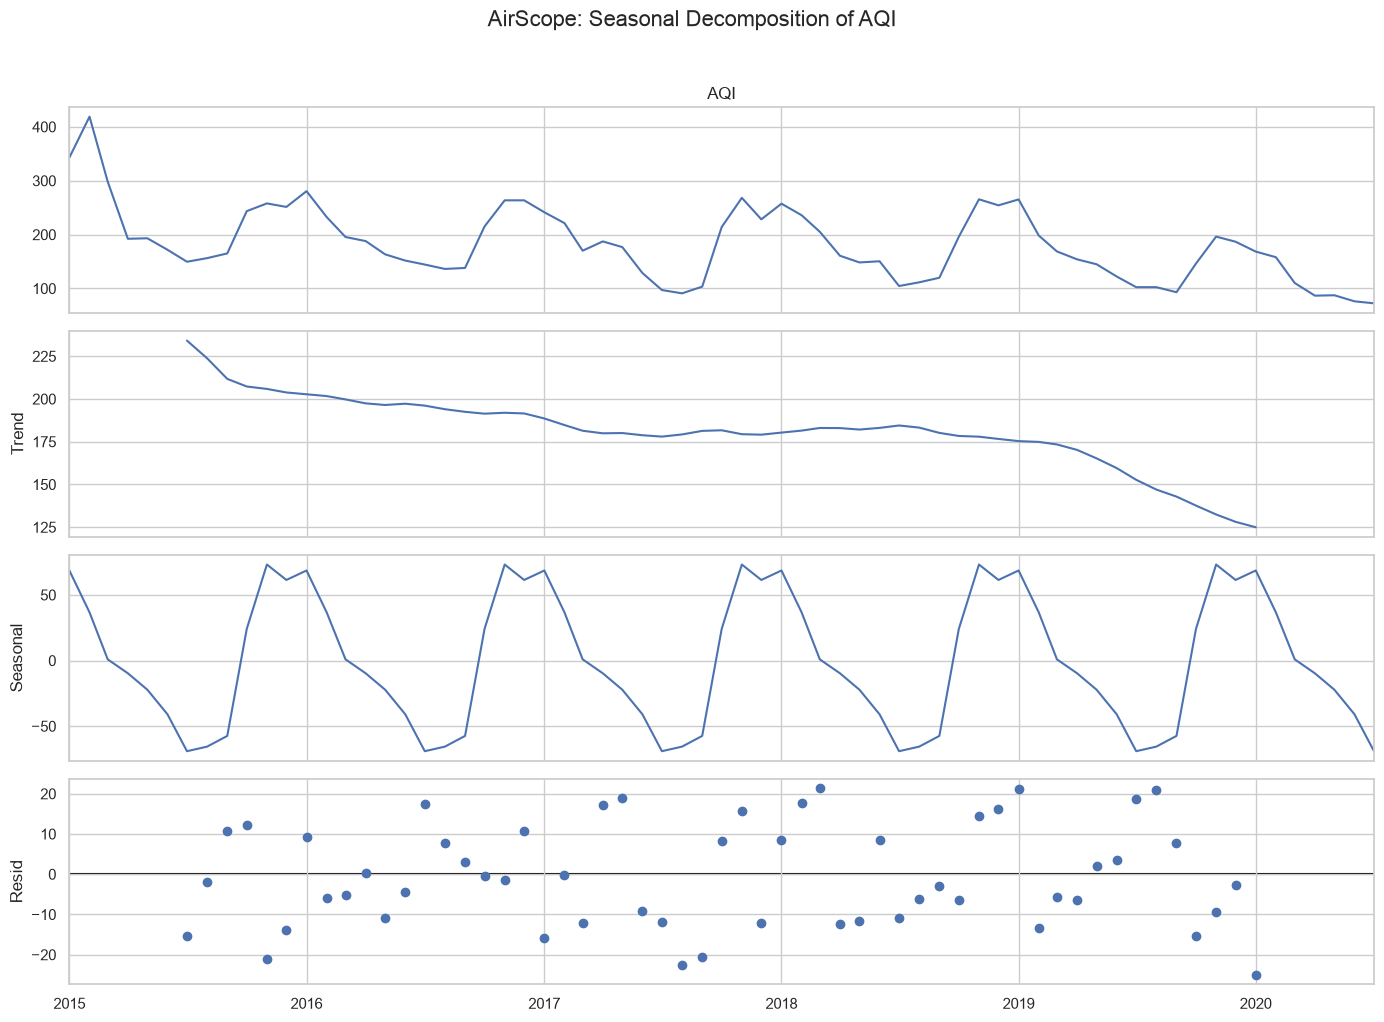

In [93]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Calculate monthly average AQI
monthly_series = (
    df.dropna(subset=["AQI"])
      .set_index("Date")["AQI"]
      .resample("MS")
      .mean()
      .sort_index()
)

# Fill missing monthly values
monthly_series = monthly_series.interpolate(
    limit_direction="both"
)

# Generate all four plots
decomposition = seasonal_decompose(
    monthly_series,
    model="additive",
    period=12
)

fig = decomposition.plot()
fig.set_size_inches(14, 10)
fig.suptitle(
    "AirScope: Seasonal Decomposition of AQI",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

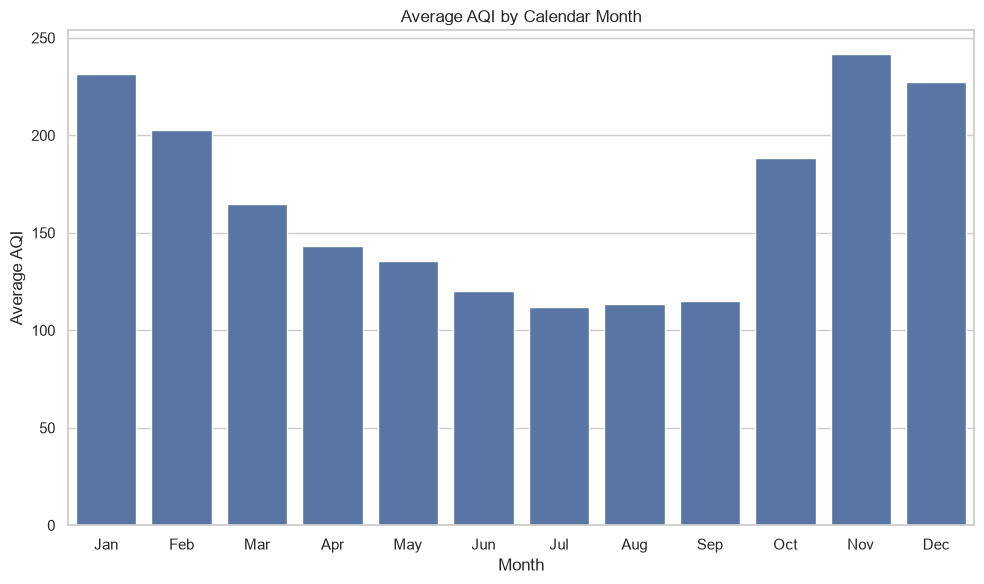

In [94]:
# Graph 19: Average AQI by Month

monthly_aqi = (
    df.dropna(subset=["AQI"])
      .groupby("Month")["AQI"]
      .mean()
      .reindex(range(1, 13))
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=monthly_aqi.index,
    y=monthly_aqi.values
)

plt.title("Average AQI by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(
    ticks=range(12),
    labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)
plt.tight_layout()
plt.show()

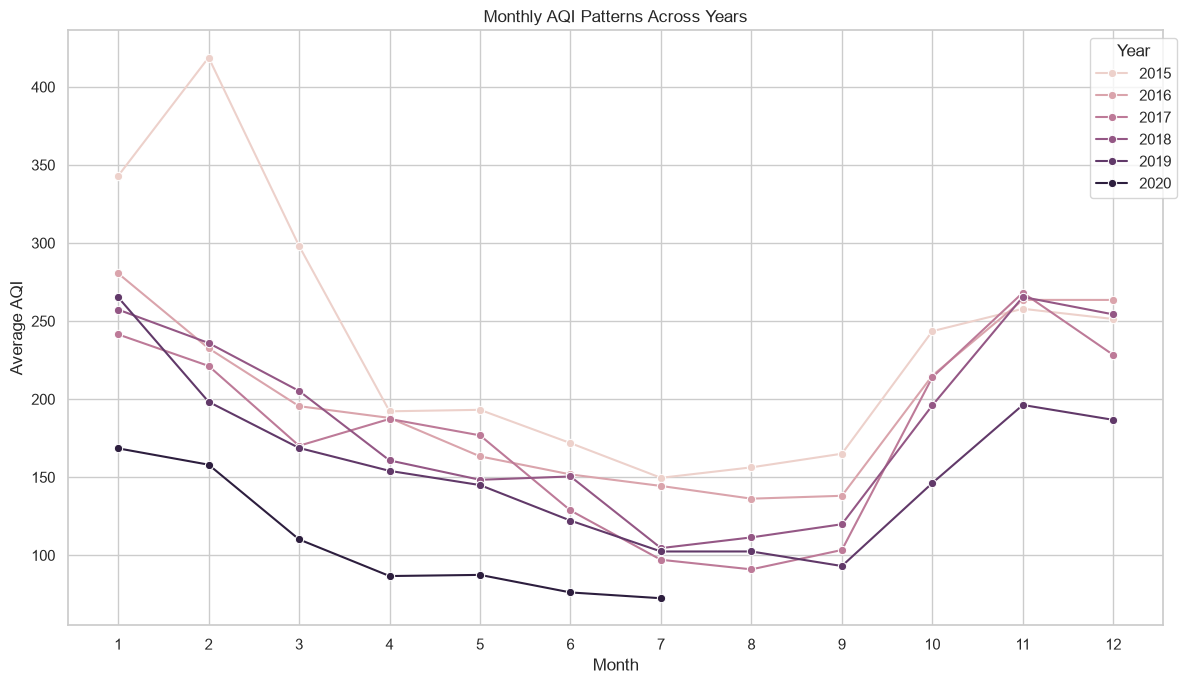

In [95]:
# Graph 20: Monthly AQI Trends Across Years

year_month_aqi = (
    df.dropna(subset=["AQI"])
      .groupby(["Year", "Month"])["AQI"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(12, 7))

sns.lineplot(
    data=year_month_aqi,
    x="Month",
    y="AQI",
    hue="Year",
    marker="o"
)

plt.title("Monthly AQI Patterns Across Years")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(range(1, 13))
plt.legend(title="Year", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

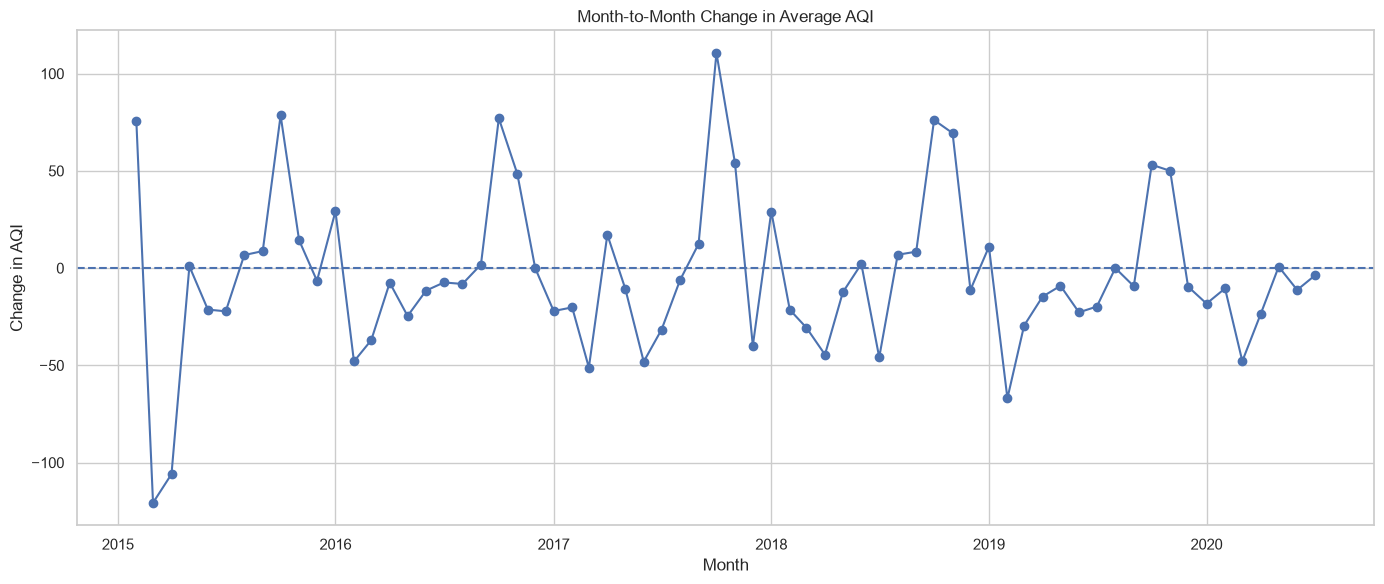

In [96]:
# Graph 21: Month-to-Month Change in AQI

monthly_series = (
    df.dropna(subset=["AQI"])
      .set_index("Date")["AQI"]
      .resample("MS")
      .mean()
)

monthly_change = monthly_series.diff()

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_change.index,
    monthly_change.values,
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.title("Month-to-Month Change in Average AQI")
plt.xlabel("Month")
plt.ylabel("Change in AQI")
plt.tight_layout()
plt.show()

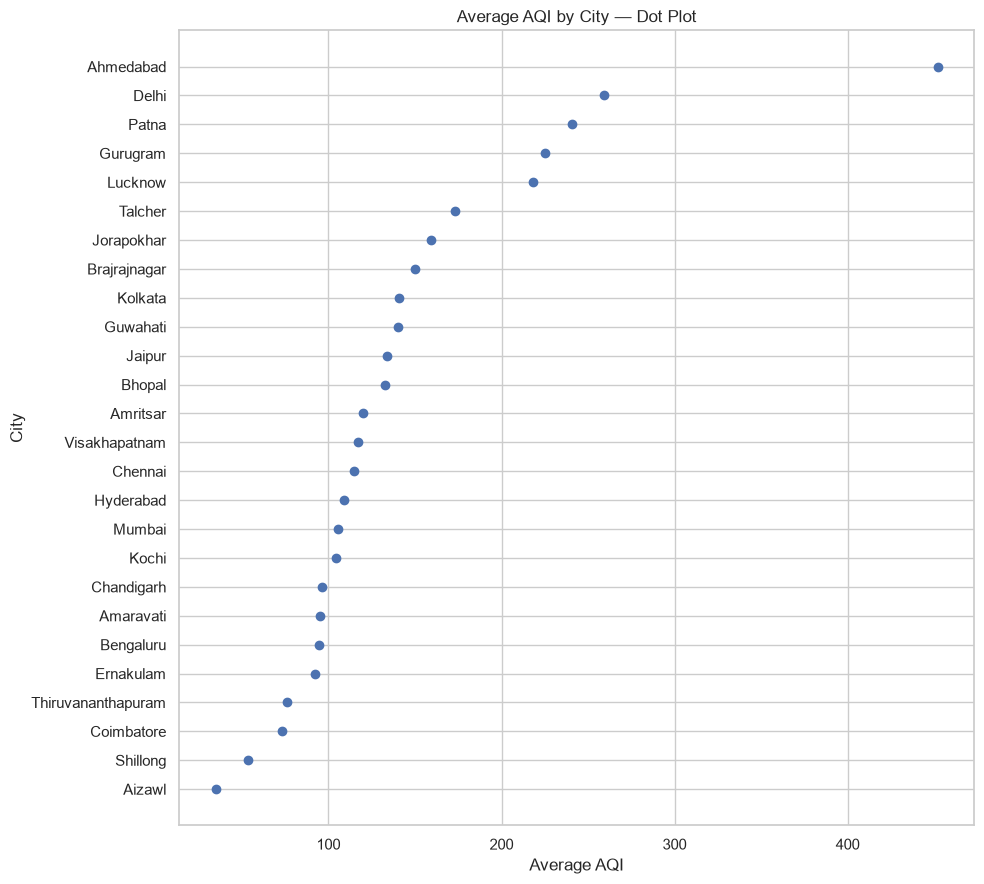

In [97]:
# Graph 22: City-wise Average AQI Dot Plot

city_aqi_dot = (
    df.groupby("City")["AQI"]
      .mean()
      .dropna()
      .sort_values()
)

plt.figure(figsize=(10, 9))

plt.scatter(
    city_aqi_dot.values,
    city_aqi_dot.index
)

plt.title("Average AQI by City — Dot Plot")
plt.xlabel("Average AQI")
plt.ylabel("City")
plt.tight_layout()
plt.show()